# Generative Mode / Decoder Probing

 OBJECTIVE:-
  - Decode individual latent dimensions back to brain image space to visualise what each dimension encodes. This provides causal, visual evidence for the
    interpretations made in notebooks 5.1, 5.7, and 5.8.

 APPROACH:-
  - Compute the mean latent vector across all training subjects (baseline)
  - For each key dimension, vary it from -3σ to +3σ in 7 steps
  - Decode each modified vector through the VAE decoder
  - Visualise the resulting brain images as a montage
  - Compute difference maps (decoded - baseline) to highlight what changes

 DIMENSIONS PROBED
   - latent_132  hypothesis: spatial position of striatum
   - latent_173  hypothesis: left-right dopamine asymmetry (laterality)
   - latent_114  hypothesis: overall signal intensity / dopamine uptake
   - latent_218  hypothesis: universal spatial encoding

 MODEL
   - β-VAE, β = 5×10⁻⁵
   - Checkpoint: beta_5.00e-05_best.pth
   - Decoder: ComplexBottleneckDeconvDecoder (latent_dim=256)

 OUTPUTS
   - results/figures/generative_latent_132.png
   - results/figures/generative_latent_173.png
   - results/figures/generative_latent_114.png
   - results/figures/generative_latent_218.png
   - results/generative/decoded_traversals.npz


## 1. Imports and Configuration

In [19]:
# [IMPORTS & CONFIG]

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import sys

sys.path.append('../../models')
from autoencoder.custom_encoder import CustomEncoder
from autoencoder.selected_model import ComplexBottleneckDeconvDecoder, BottleneckAE

CHECKPOINT_PATH = '../../models/checkpoints/beta_5.00e-05_best.pth'
LATENT_PATH = '../../data/baseline/train_mu_beta_5.00e-05.csv'

# Dynamically choose MPS, CUDA, or fallback to CPU
if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print(f"Using device: {DEVICE}")


Using device: mps


## 2. Load Model

In [20]:
# [LOAD-MODEL]

class VAEWrapper(torch.nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def encode(self, x):
        mu, log_var = self.model.encoder(x)
        return mu

    def decode(self, z):
        # z: (1, 256) → decoder expects (1, 256, 1, 1, 1)
        z = z.unsqueeze(-1).unsqueeze(-1).unsqueeze(-1)
        return self.model.decoder(z)

    def forward(self, x):
        mu, log_var = self.model.encoder(x)
        recon = self.model.decoder(mu.unsqueeze(-1).unsqueeze(-1).unsqueeze(-1))
        return recon, mu, log_var

encoder = CustomEncoder(initial_filters=32, latent_dim=256)
decoder = ComplexBottleneckDeconvDecoder(latent_dim=256, target_shape=(64, 128, 128))
model   = BottleneckAE(encoder, decoder)
model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=DEVICE))
model.eval()
model.to(DEVICE)
vae = VAEWrapper(model)
vae.eval()
print("Model loaded.")

Model loaded.


## 3. Compute Mean and STD

In [21]:
# [BASELINE]
    # Compute mean and std of each latent dimension across training subjects

df_train = pd.read_csv(LATENT_PATH)
latent_cols = [c for c in df_train.columns if c.startswith('latent_')]

mu_mean = df_train[latent_cols].mean().values.astype(np.float32)  # (256,)
mu_std  = df_train[latent_cols].std().values.astype(np.float32)   # (256,)

print(f"Training subjects: {len(df_train)}")
print(f"Latent dims: {len(latent_cols)}")
print(f"Mean vector range: [{mu_mean.min():.2f}, {mu_mean.max():.2f}]")
print(f"Std vector range:  [{mu_std.min():.2f}, {mu_std.max():.2f}]")

Training subjects: 3085
Latent dims: 256
Mean vector range: [-0.95, 1.26]
Std vector range:  [0.04, 1.02]


## 4. Test the Decoder

Input z shape: torch.Size([1, 256])
Decoded output shape: torch.Size([1, 1, 64, 128, 128])
Value range: [-0.168, 3.196]


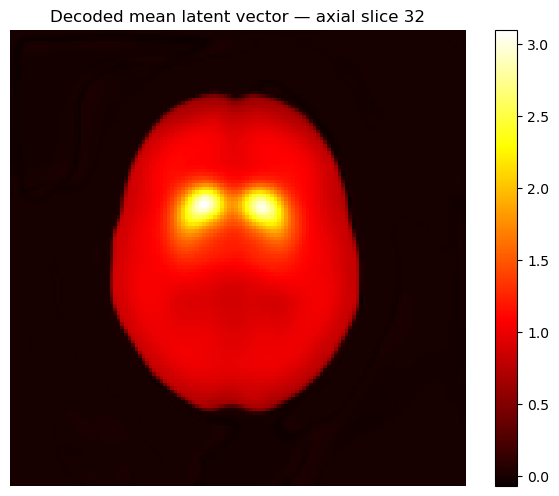

In [22]:
# [TEST-DECODER]
    # Decode the mean vector and check output shape

z_mean = torch.tensor(mu_mean).unsqueeze(0).to(DEVICE)  # (1, 256)
print(f"Input z shape: {z_mean.shape}")

with torch.no_grad():
    recon = vae.decode(z_mean)

print(f"Decoded output shape: {recon.shape}")
print(f"Value range: [{recon.min().item():.3f}, {recon.max().item():.3f}]")

# Quick visualisation — middle axial slice
recon_np = recon.cpu().numpy()[0, 0]  # (64, 128, 128)
mid_slice = recon_np[32]               # axial slice at depth 32

plt.figure(figsize=(6, 5))
plt.imshow(mid_slice, cmap='hot')
plt.colorbar()
plt.title('Decoded mean latent vector — axial slice 32')
plt.axis('off')
plt.tight_layout()
plt.show()  

## 5. Latent Traversal
The idea:- The VAE has compressed every brain scan into a point in a 256-dimensional space. Each dimension is a number. Latent traversal means: pick one dimension, move it from one extreme to the other in small steps, decode each point back to a brain image, and watch what changes.

In [23]:
# [LATENT-TRAVERSAL]
    # For each key dimension, vary from -3σ to +3σ and decode

KEY_DIMS = {
    'latent_132': 132,
    'latent_173': 173,
    'latent_114': 114,
    'latent_218': 218,
}
N_STEPS = 7
STEPS = np.linspace(-3, 3, N_STEPS)  # in units of σ

traversals = {}  # dim_name → (N_STEPS, 64, 128, 128)

for dim_name, dim_idx in KEY_DIMS.items():
    print(f"Traversing {dim_name}...")
    vols = []
    for step in STEPS:
        z = mu_mean.copy()
        z[dim_idx] = mu_mean[dim_idx] + step * mu_std[dim_idx]
        z_tensor = torch.tensor(z).unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            recon = vae.decode(z_tensor)
        vols.append(recon.cpu().numpy()[0, 0])  # (64, 128, 128)
    traversals[dim_name] = np.stack(vols)  # (7, 64, 128, 128)
    print(f"  Done. Shape: {traversals[dim_name].shape}")

# Save
os.makedirs('../../results/generative', exist_ok=True)
np.savez('../../results/generative/decoded_traversals.npz', **traversals)
print("\nAll traversals saved.")

Traversing latent_132...
  Done. Shape: (7, 64, 128, 128)
Traversing latent_173...
  Done. Shape: (7, 64, 128, 128)
Traversing latent_114...
  Done. Shape: (7, 64, 128, 128)
Traversing latent_218...
  Done. Shape: (7, 64, 128, 128)

All traversals saved.


## 6. Visualize

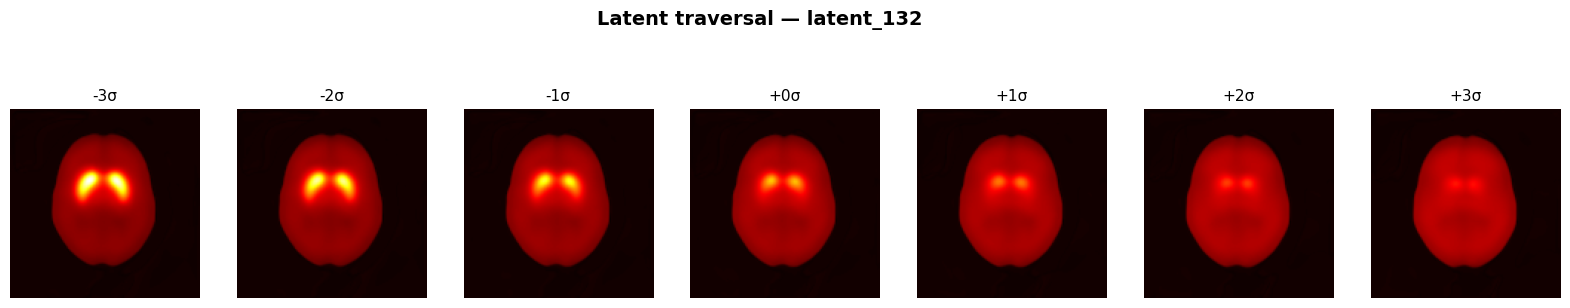

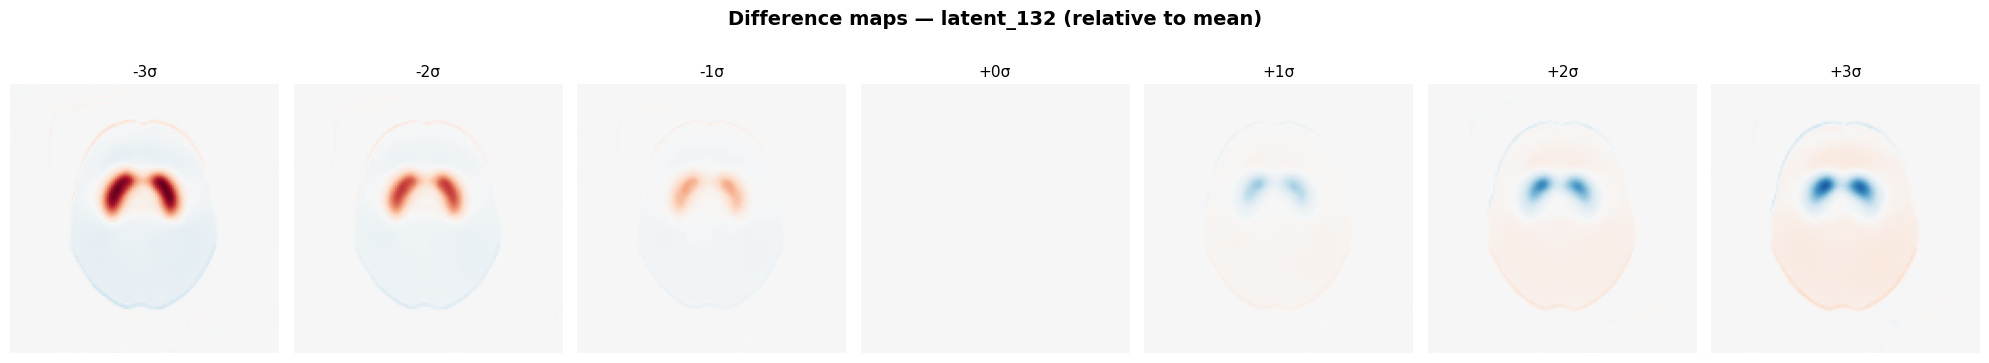

Saved: generative_latent_132.png


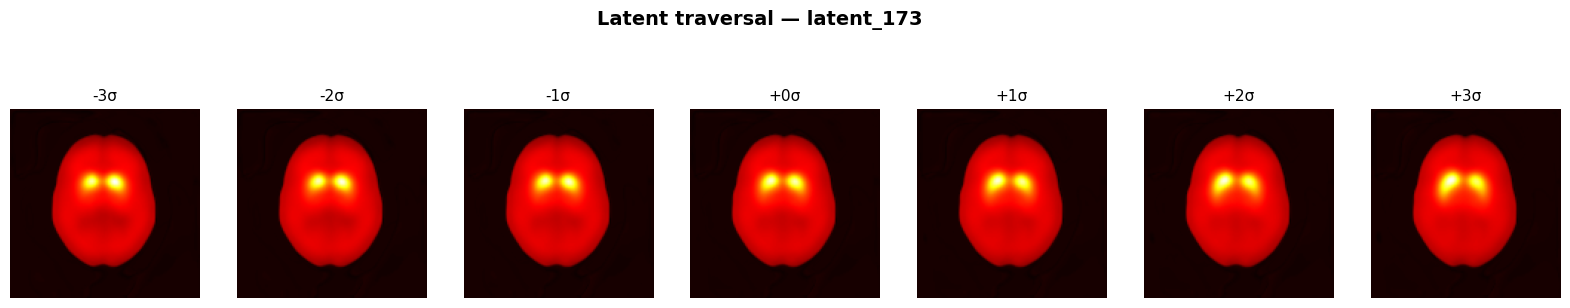

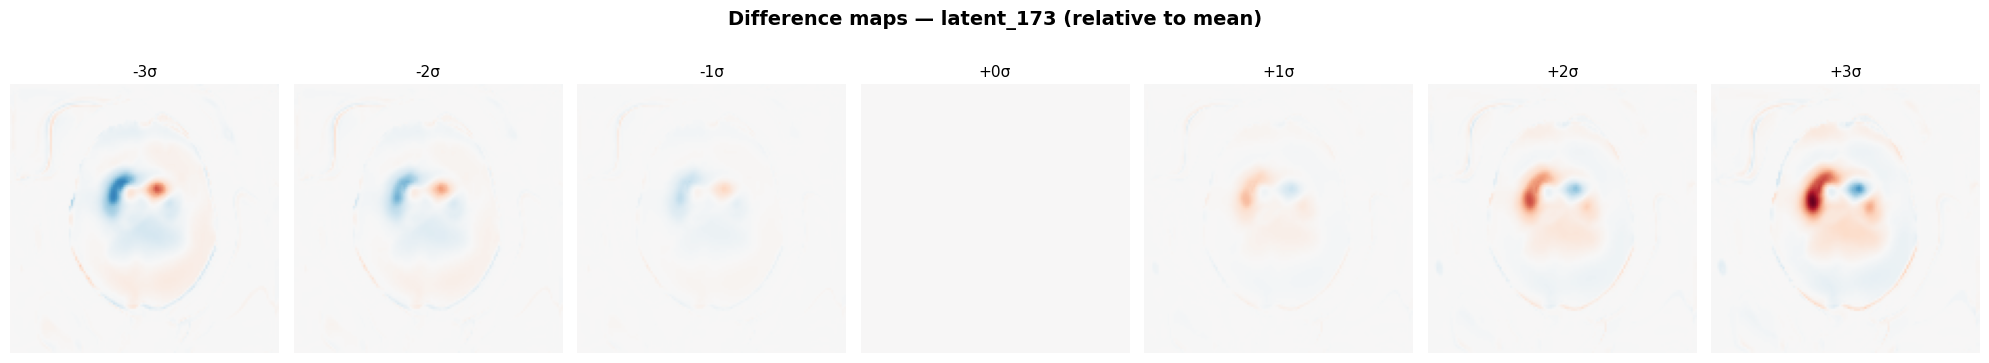

Saved: generative_latent_173.png


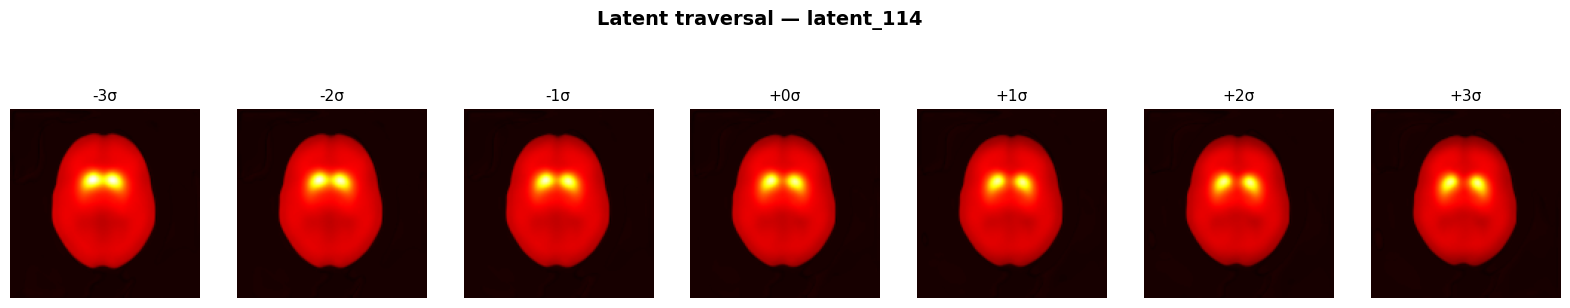

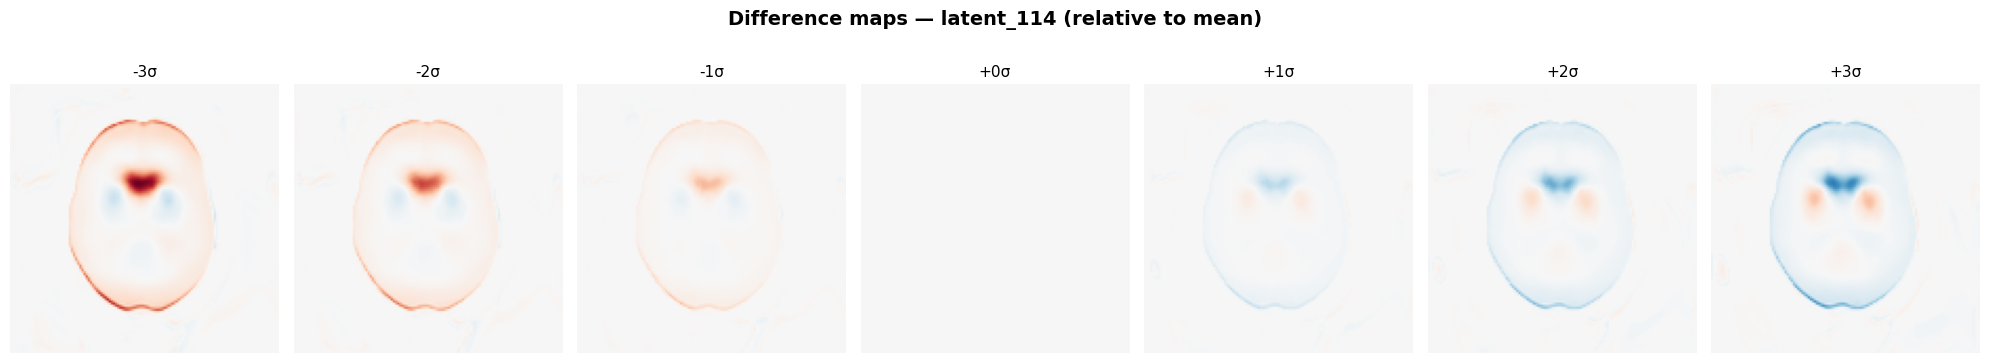

Saved: generative_latent_114.png


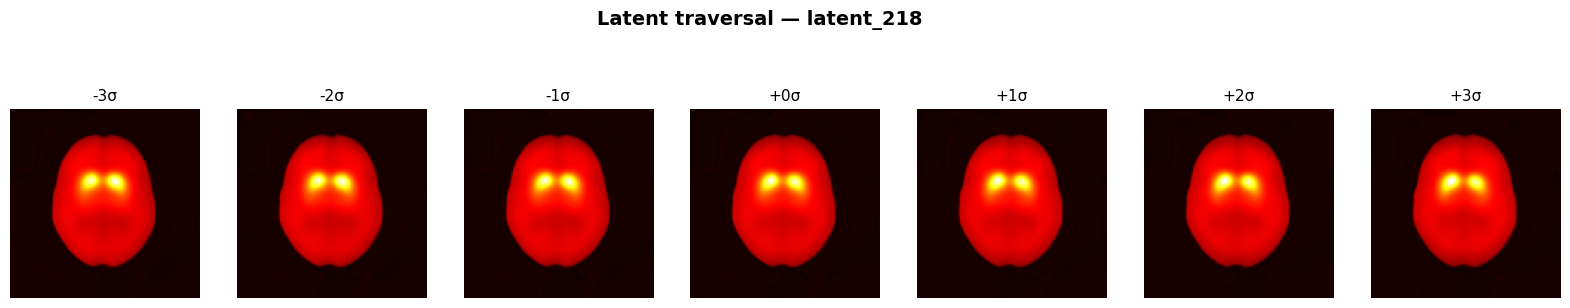

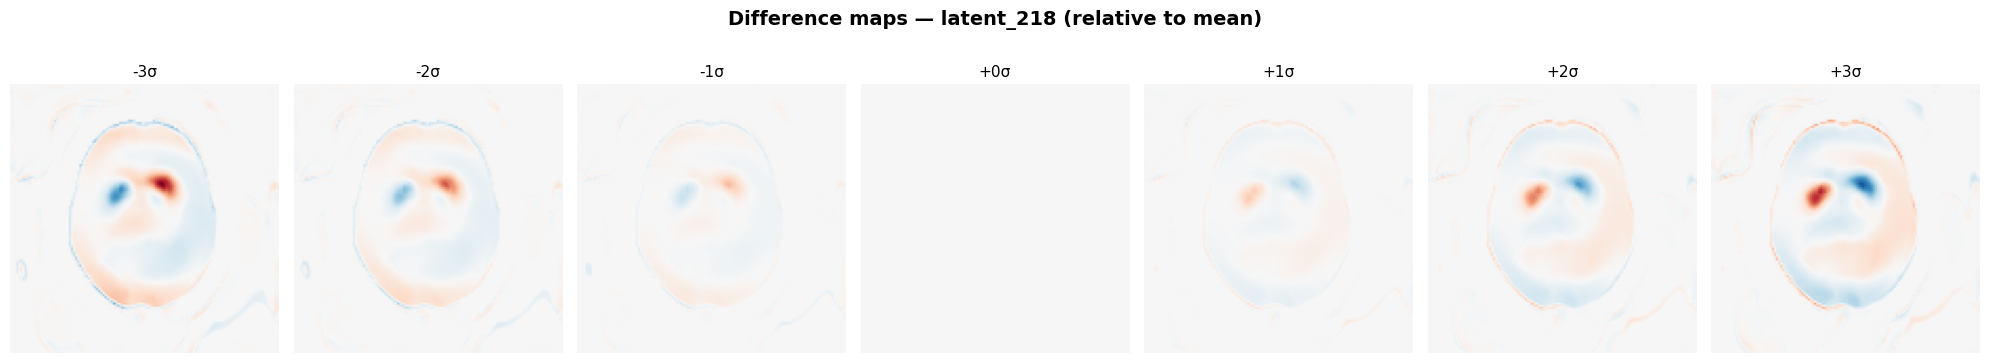

Saved: generative_latent_218.png


In [24]:
# [VISUALISE-TRAVERSALS]

SLICE_IDX = 32  # middle axial slice
STEP_LABELS = [f'{s:+.0f}σ' for s in STEPS]

for dim_name, vols in traversals.items():
    fig, axes = plt.subplots(1, N_STEPS, figsize=(20, 4))
    fig.suptitle(f'Latent traversal — {dim_name}', fontsize=14, fontweight='bold')

    # Use consistent colorscale across all 7 steps
    vmin = vols[:, SLICE_IDX, :, :].min()
    vmax = vols[:, SLICE_IDX, :, :].max()

    for i, ax in enumerate(axes):
        ax.imshow(vols[i, SLICE_IDX], cmap='hot', vmin=vmin, vmax=vmax)
        ax.set_title(STEP_LABELS[i], fontsize=11)
        ax.axis('off')

    # Difference maps row — show change relative to baseline (step 3, index 3)
    fig2, axes2 = plt.subplots(1, N_STEPS, figsize=(20, 4))
    fig2.suptitle(f'Difference maps — {dim_name} (relative to mean)', fontsize=14, fontweight='bold')
    baseline_slice = vols[3, SLICE_IDX]  # mean vector step

    diff_max = np.abs(vols[:, SLICE_IDX] - baseline_slice).max()

    for i, ax in enumerate(axes2):
        diff = vols[i, SLICE_IDX] - baseline_slice
        im = ax.imshow(diff, cmap='RdBu_r', vmin=-diff_max, vmax=diff_max)
        ax.set_title(STEP_LABELS[i], fontsize=11)
        ax.axis('off')

    plt.tight_layout()

    fig.savefig(f'../../results/figures/generative_{dim_name}.png', dpi=150, bbox_inches='tight')
    fig2.savefig(f'../../results/figures/generative_{dim_name}_diff.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: generative_{dim_name}.png")